In [10]:
from pathlib import Path # class 'Path' that helps locating the files
from ase import Atoms # class 'Atoms' represents atomic structures

import numpy as np

from dscribe.descriptors import ACSF # library for generating descriptors of atomic structures
from joblib import Parallel, delayed
from joblib import cpu_count
from threadpoolctl import threadpool_limits

import os

import matplotlib.pyplot as plt


# Libraries for the NN
import copy
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [11]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        )
    )

PyTorch version: 2.14.1+cpu
CUDA available: False
CUDA version: None


In [12]:

TOTAL_CPUS = cpu_count(only_physical_cores=False) # Detect available logical CPU cores


N_JOBS = max(1, TOTAL_CPUS - 5) # Reserve two CPUs for the operating system, if possible

print(f"Available CPUs: {TOTAL_CPUS}")
print(f"CPUs allocated: {N_JOBS}")

Available CPUs: 32
CPUs allocated: 27


In [13]:
def _parse_n2p2_block(block): # Internal Helper function to parse a single n2p2 block and extract atomic structure and energy information from the lines in n2p2 file
    symbols = []                # block - lines belongs to one atomic configuration
    positions = []
    cell = []
    energy = None


    for line in block:
        parts = line.split() # separate the strings in a line based on whitespace

        if not parts:
            continue # if the list parts is empty, skip to next line

        if parts[0] == "lattice":
            cell.append([float(x) for x in parts[1:4]]) # Make the vector with direction values of [x,y,z] ex - from "lattice 0.0 5.0 0.0" extract [0.0, 5.0, 0.0]
            has_cell = True # lattice information for this block is found successfully

        elif parts[0] == "atom":
            positions.append([float(x) for x in parts[1:4]]) # poistion of the atom to the list positions, ex - from "atom 0.0 0.0 0.0 H" extract [0.0, 0.0, 0.0]
            symbols.append(parts[4]) # Type of atom to the list symbols, ex - from "atom 0.0 0.0 0.0 Si" extract "Si"
                                       # ignores all the other information in the line, like charge, mass, etc. 

        elif parts[0] == "energy":
            energy = float(parts[1]) # extract the reference energy value

    if energy is None:
        raise ValueError("Energy missing in n2p2 block") # raising an error if energy is not found in the block

   # if not symbols:
        #raise ValueError("No atoms found in n2p2 block") # raising an error if no atoms are found in the block

    atoms = Atoms( #Converst extracted information into ASE Atoms object
        symbols=symbols,
        positions=positions,
        cell=cell if len(cell) == 3 else None,
        pbc=(len(cell) == 3) 
    )

    return atoms, energy

In [14]:
def read_n2p2(path, n_jobs=N_JOBS): # function to read the entire dataset from n2p2 file

    current_block = []
    blocks = [] # temporarily stores the lines of one configuration
    inside = False # tracks whether Python is currently reading a configuration

    with open(path, "r") as f: # 'as file' assignss the opened file to the variable 'file' which can be used to read the file 
        for line in f:
            line = line.strip() #.strip() method removes whitespace at the beginning and end of each line, including newline characters

            if line == "begin": # when encounters 'begin', it knows a new atomic configuration is starting
                current_block = []
                inside = True # program is now reading a configuration

            elif line == "end" and inside: 
                blocks.append(current_block)
                inside = False

            elif inside:
                current_block.append(line)

    results = Parallel(
        n_jobs=n_jobs,
        backend="loky"
    )(
        delayed(_parse_n2p2_block)(block)
        for block in blocks
    )

    atoms_list = [item[0] for item in results]
    energies = np.array([item[1] for item in results])

    return atoms_list, energies


atoms_list, energies = read_n2p2(
    "input.data",
    n_jobs=N_JOBS
)

print("Number of structures:", len(atoms_list))
print("Energy shape:", energies.shape)

Number of structures: 28000
Energy shape: (28000,)



##### Number of ACSF Features per Atom


The actual number depends on the chosen chemical species and ACSF parameters.

 with **two chemical species**, **three G2 parameter sets**, and **two G4 parameter sets**, DScribe's ACSF feature count is:

$$
N_{\text{features}} =
N_{\text{species}}
+ N_{\text{species}}N_{G2}
+ \frac{N_{\text{species}}(N_{\text{species}}+1)}{2}N_{G4}
$$

Substituting the values:

$$
= 2 + (2 \times 3) + (3 \times 2) = 14
$$

The first term represents the default **G1 radial features**, which are included by DScribe even though G1 parameters were not explicitly specified.

For two species, the code therefore produces **14 ACSF features per atom**.


In [15]:
species = sorted({
    symbol
    for atoms in atoms_list #loop tzhrough every atomic structure in the list of structures
    for symbol in atoms.get_chemical_symbols() # give chemcial sxymbols of each atom in the structure, remove duplicates in list atoms
})

acsf = ACSF(
    species=species,
    r_cut=6.0,
    g2_params=[ # parameters for the radial symmetry functions
        [1.0, 0.0],
        [1.0, 2.0],
        [1.0, 4.0]
    ],
    g4_params=[
        [1.0, 1.0, 1.0], # parameters for the angular symmetry functions
        [1.0, 1.0, -1.0]
    ]
)


def calculate_atomic_descriptors(atoms):
    
    return np.asarray(
        acsf.create(atoms, n_jobs=1), # Calculates ACSF descriptors for all atoms in the structure, matrix of shape (n_atoms, n_features)
                                        # Requests only one job - because already distributing separate structures across multiple worker processes in the outer function
        dtype=np.float32  # to reduce memory consumption converts to 32 bit floats
    )


def build_descriptors(atoms_list, n_jobs=N_JOBS):

    
    descriptors = Parallel(
        n_jobs=n_jobs,
        backend="loky"
    )(
        delayed(calculate_atomic_descriptors)(atoms)
        for atoms in atoms_list
    )

    return descriptors # calculated descriptors returning


X = build_descriptors(
    atoms_list,
    n_jobs=N_JOBS #save descriptors foe each atom separately instead of averaging
)


Z = [
    atoms.get_atomic_numbers().astype(np.int64) # Identify atomic number of each atom in the structure, 64 bit integers
    for atoms in atoms_list
]

energies = np.asarray(energies, dtype=np.float32)

print("Number of structures:", len(X))
print("First structure descriptor shape:", X[0].shape) #(n_atoms, n_Features)
print("First structure atomic numbers:", Z[0]) 
print("Number of ACSF features:", acsf.get_number_of_features())


Number of structures: 28000
First structure descriptor shape: (108, 6)
First structure atomic numbers: [13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13
 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13
 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13
 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13
 13 13 13 13 13 13 13 13 13 13 13 13]
Number of ACSF features: 6


# TASK 3 - Train a Neural Network


##### Main Idea: Total Energy Prediction

The main idea is:

$$
\boxed{
E_{\text{total}} = \sum_{i=1}^{N_{\text{atoms}}} E_i
}
$$

Each atom has its own descriptor vector. A neural network predicts its energy contribution, and the contributions are summed to obtain the **total energy of the structure**.


#### weighted sum

Each neuron calculates a weighted sum:

$$
z = \sum_i w_i x_i + b
$$

`nn.ReLU()` applies the activation function: it introduce non linearity

$$
ReLU(z) = \max(0,z)
$$



##### Normalize the reference energy



$$
\boxed{
y_s = \frac{E_s/N_s - \mu_E}{\sigma_E}
}
$$

where:

- $E_s$ = reference total energy of structure $s$
- $N_s$ = number of atoms
- $\mu_E$ = training mean energy per atom
- $\sigma_E$ = training standard deviation of energy per atom


In [17]:

N_THREADS = max(1, N_JOBS) # ensure number of working threads is at least one

torch.set_num_threads(N_THREADS) # tells PyTorch how many CPU threads it may use


try:                                                # limits inter operation parallelism to one thread
    torch.set_num_interop_threads(1)                # Inter-operation parallelism concerns the execution of independent operations
except RuntimeError:                                #  (intra-operation parallelism concerns parallel work within an individual operation)
    pass


DEVICE = torch.device( # automatically select GPU if available
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Selected device: {DEVICE}")

if DEVICE.type == "cuda":
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    print(f"GPU count: {torch.cuda.device_count()}")
else:
    print("CUDA GPU unavailable. Using CPU.") # use CPU if GPU is not available

torch.manual_seed(42) # random seeds for PyTorch and NumPy, to make results reproducible, including the initial neural network weights
np.random.seed(42)

print(f"Device: {DEVICE}")
print(f"CPU threads: {torch.get_num_threads()}") # PyTorch intra operation thread setting




indices = np.arange(len(X)) # array containing the indices of all structures, to split structures without changing the correspondence between descriptors, atomic numbers and energies

train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.2, # 0.2 for testing , other 0.8 for train and validation
    random_state=42
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.2, # 0.2 of the remaining 0.8 of above for validation
    random_state=42
)   

# if configurations are closely related a random split can give an overly optimistic estimate of generalization ?????

print(f"Training structures: {len(train_idx)}") 
print(f"Validation structures: {len(val_idx)}")
print(f"Testing structures: {len(test_idx)}")




X_train_atoms = np.concatenate( # joins the atomic descriptor matrices vertically
    [X[i] for i in train_idx], # selects only the training structures
    axis=0
)

scaler = StandardScaler() # for each descriptor feature, it calculates the training mean and standard deviation and standardize (only using training atoms)
scaler.fit(X_train_atoms)


X_scaled = [
    scaler.transform(x).astype(np.float32) # apply the fitted scalar to every structure
    for x in X
]

print("Descriptor scaling completed")




train_energy_per_atom = np.array([ # calculate reference energy per atom in each structure = Total reference energy of s structure / Number of atoms in the structure 
    energies[i] / len(Z[i])
    for i in train_idx
])

energy_mean = float(train_energy_per_atom.mean()) # calculates the mean of the training structures' energies per atom
energy_std = float(train_energy_per_atom.std()) # standard deviation

if energy_std < 1e-12: # prevents division by an extremely small number during normalization
    energy_std = 1.0

print(f"Energy mean: {energy_mean:.6f} eV/atom")
print(f"Energy std: {energy_std:.6f} eV/atom")




class AtomicDataset(Dataset): # class tells PyTorch how to access atomic structures, atomic numbers and reference energies

    def __init__(self, indices, X_scaled, Z, energies): # this is executed when create an AtomicDataset object
        self.indices = list(indices)
        self.X_scaled = X_scaled
        self.Z = Z
        self.energies = energies

    def __len__(self): # how many structures belong to training set
        return len(self.indices)

    def __getitem__(self, index):

        i = self.indices[index] # converts the dataset's local index into the corresponding original structure index

        descriptors = torch.tensor( # converts the atomic descriptor matrix into a PyTorch tensor
            self.X_scaled[i],
            dtype=torch.float32
        )

        atomic_numbers = torch.tensor( # onverts atomic numbers into a tensor of 64-bit integers
            self.Z[i], 
            dtype=torch.long
        )

        energy = torch.tensor( # reference energies to a tensor
            self.energies[i],
            dtype=torch.float32
        )

        return descriptors, atomic_numbers, energy



def collate_structures(batch): # different structures may have different number of atoms, there combine multiple structures into one batch

    descriptors, atomic_numbers, energies_batch = zip(*batch) #  *batch operation unpacks the items and zip() groups the corresponding components together

    n_atoms = torch.tensor(
        [len(z) for z in atomic_numbers],
        dtype=torch.long
    )

    structure_ids = torch.repeat_interleave(
        torch.arange(len(batch)),
        n_atoms
    )

    return (
        # descriptors is a list since it cannot be directly stacked into a regular 3d tensor because their first dimensions differ
        torch.cat(descriptors, dim=0),
        torch.cat(atomic_numbers, dim=0),
        torch.stack(energies_batch),
        structure_ids,
        n_atoms
    )


train_dataset = AtomicDataset( # create training dataset using only the training indices
    train_idx, X_scaled, Z, energies
)

val_dataset = AtomicDataset( # validation set
    val_idx, X_scaled, Z, energies
)
 
test_dataset = AtomicDataset( # test set
    test_idx, X_scaled, Z, energies
)

BATCH_SIZE = 128 # NN process 128 structures per batch

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE, # load up to 128 structures per batch
    shuffle=True, # randomize the training order each epoch
    num_workers=0, # just dataLoader itself is not using multiprocessing, calculations still use it
    pin_memory=(DEVICE.type == "cuda"),
    collate_fn=collate_structures # batching function
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False, # no need to randomize
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
    collate_fn=collate_structures
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False, # no need to randomize
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
    collate_fn=collate_structures
)




class AtomicNN(nn.Module): # define nn -  predicts one atomic energy contribution from an atom's descriptor vector

    def __init__(self, n_features): # n_features - number of acsf featiures per atom
        super().__init__()

        self.network = nn.Sequential( 
            nn.Linear(n_features, 64), # hidden layer 1 - 64 neurons + ReLu, hidden layer 2 - 32 neurons + ReLu
            nn.ReLU(),
            nn.Linear(64, 32), # mapping layer 1 to layer 2
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x): # how the input passes through the neural network
        return self.network(x).squeeze(-1) # .network(x) calculates the outputs, .squeeze(-1) removes the final dimension of size one - produces one energy contribution for each atom ?????



class AtomwisePotential(nn.Module): # potential model

    def __init__(self, n_features, elements): # 
        super().__init__()

        self.networks = nn.ModuleDict({ # creates a separate atomic neural network for every chemical element
            str(int(z)): AtomicNN(n_features)
            for z in elements
        })

    def forward(
        self,
        descriptors,
        atomic_numbers,
        structure_ids=None,
        n_structures=None
    ):

        atomic_energies = torch.zeros(
            len(atomic_numbers),
            dtype=descriptors.dtype,
            device=descriptors.device
        )

        for element, network in self.networks.items():

            mask = atomic_numbers == int(element)

            if mask.any():

                atomic_energies[mask] = network(
                    descriptors[mask]
                )

        # Single structure prediction
        if structure_ids is None:
            return atomic_energies.sum()

        # Multiple structure prediction
        structure_energies = torch.zeros(
            n_structures,
            dtype=descriptors.dtype,
            device=descriptors.device
        )

        structure_energies.index_add_(
            0,
            structure_ids,
            atomic_energies
        )

        return structure_energies

elements = sorted(set( # Collects all unique atomic numbers in dataset
    int(z)
    for numbers in Z
    for z in numbers
))

n_features = X[0].shape[1] #finds the number of ACSF features per atom

model = AtomwisePotential(
    n_features=n_features,
    elements=elements
).to(DEVICE) # creates the complete atom wise potential and moves it to the

print("Atomic elements:", elements)
print(model)



optimizer = torch.optim.Adam( # optimizer updates the neural network parameters during training to reduce prediction error
    model.parameters(), # supplies the trainable weights and biases
    lr=0.001 # learning rate
)

criterion = nn.MSELoss() # Mean Squared Error as the loss function, try to mi´nimize this value

MAX_EPOCHS = 500 # control how long it trakes , maximum of 500 complete passes through the training dataset
PATIENCE = 30 # after 30 consecutive epochs , wait for validation improvement
MIN_DELTA = 1e-6 # minimum decrease in validation loss required to count as an improvement

best_val_loss = float("inf") # initializes the best validation loss to positive infinity
best_model_state = None  # stores best model parameters
best_epoch = 0 # stores epoch where the best model was obtained
epochs_without_improvement = 0 # stores number of consecutive epochs without sufficient improvement

train_history = [] # empty lists for storing training and validation losses after each epoch
val_history = []




def run_epoch(loader, training=True):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_samples = 0

    for x, z, targets, structure_ids, n_atoms in loader:

        # Transfer entire batch to GPU
        x = x.to(DEVICE, non_blocking=True)
        z = z.to(DEVICE, non_blocking=True)

        targets = targets.to(
            DEVICE, non_blocking=True
        )

        structure_ids = structure_ids.to(
            DEVICE, non_blocking=True
        )

        n_atoms = n_atoms.to(
            DEVICE, non_blocking=True
        )

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            # Predict all structures in the batch
            predictions = model(
                x,
                z,
                structure_ids,
                len(targets)
            )

            # Normalize predicted energy
            predictions = predictions / n_atoms

            # Normalize reference energy
            target_residuals = (
                targets - energy_mean * n_atoms
            ) / (energy_std * n_atoms)

            loss = criterion(
                predictions,
                target_residuals
            )

            if training:
                loss.backward()
                optimizer.step()

        batch_size = len(targets)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


print("\nStarting neural network training...\n")

for epoch in range(MAX_EPOCHS):

    
    train_loss = run_epoch( # training loss
        train_loader,
        training=True
    )

    
    val_loss = run_epoch( # validation loss
        val_loader,
        training=False
    )

    train_history.append(train_loss)
    val_history.append(val_loss)

    
    if val_loss < best_val_loss - MIN_DELTA: # save the best model

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    
    if (epoch + 1) % 50 == 0: # print every 50 epochs

        print(
            f"Epoch {epoch+1}/{MAX_EPOCHS} | "
            f"Train Loss: {train_loss:.8f} | "
            f"Val Loss: {val_loss:.8f}"
        )

    
    if epochs_without_improvement >= PATIENCE: # stop when validation loss stops improving

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )

        break


model.load_state_dict(best_model_state) # restores the model parameters saved at the best validation epoch - the final training epoch is not necessarily the epoch with the lowest validation loss

print("\nTraining completed!")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.8f}")
print(f"Total epochs executed: {len(train_history)}")



plt.figure(figsize=(9, 5)) # plot training and validation losses

plt.plot(
    range(1, len(train_history) + 1),
    train_history,
    label="Training Loss"
)

plt.plot(
    range(1, len(val_history) + 1),
    val_history,
    label="Validation Loss"
)

plt.axvline( # where the best validation loss was recorded
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Normalized MSE Loss")
plt.title("Atom-wise Neural Network Training")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



torch.save( # save trained model
    {
        "model_state_dict": model.state_dict(),
        "elements": elements,
        "n_features": n_features,
        "energy_mean": energy_mean,
        "energy_std": energy_std,
        "scaler_mean": scaler.mean_,
        "scaler_scale": scaler.scale_,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "train_history": train_history,
        "val_history": val_history
    },
    "atomwise_mlip_model.pth"
) # does not currently save the ACSF configuration , do we need to??? do we need them making predictions on new atomic structures?????

print("Model saved as atomwise_mlip_model.pth")
print(epochs_without_improvement)


Selected device: cpu
CUDA GPU unavailable. Using CPU.
Device: cpu
CPU threads: 27
Training structures: 17920
Validation structures: 4480
Testing structures: 5600
Descriptor scaling completed
Energy mean: -3.554907 eV/atom
Energy std: 0.112871 eV/atom
Atomic elements: [13]
AtomwisePotential(
  (networks): ModuleDict(
    (13): AtomicNN(
      (network): Sequential(
        (0): Linear(in_features=6, out_features=64, bias=True)
        (1): ReLU()
        (2): Linear(in_features=64, out_features=32, bias=True)
        (3): ReLU()
        (4): Linear(in_features=32, out_features=1, bias=True)
      )
    )
  )
)

Starting neural network training...

Epoch 50/500 | Train Loss: 0.00743081 | Val Loss: 0.00756322
Epoch 100/500 | Train Loss: 0.00736282 | Val Loss: 0.00780793


KeyboardInterrupt: 

# TASK 4

MAE: 0.760834 eV
RMSE: 1.039270 eV


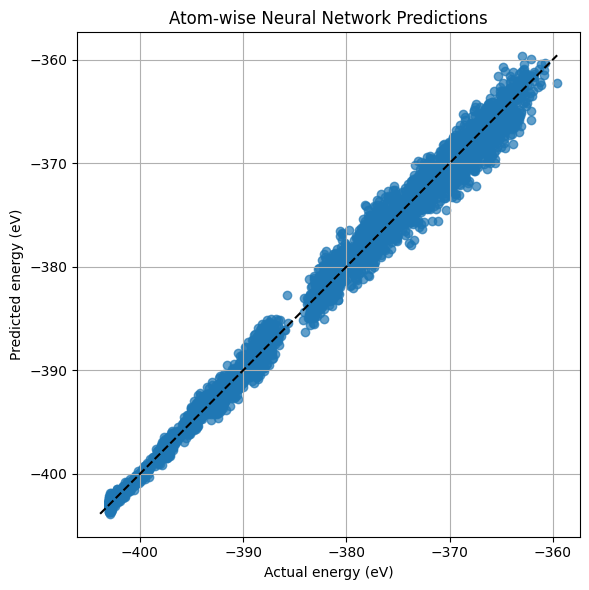

In [8]:




def predict_structures(model, indices, X_scaled, Z):

    model.eval()
    predictions = [] # store the predicted total energies of all test structures

    with torch.no_grad(): # tells PyTorch not to calculate or store gradients during prediction - reduces memory consumption, but if later calculate atomic forces using energy derivatives, will need gradient tracking

        for i in indices:

            x = torch.tensor( # retrieves the scaled ACSF descriptors for structure
                X_scaled[i],
                dtype=torch.float32,
                device=DEVICE
            )

            z = torch.tensor( # retrieves the atomic numbers of the atoms in structure
                Z[i],
                dtype=torch.long,
                device=DEVICE
            )

            residual = model(x, z) # calls the trained model

            
            total_energy = ( # reverses the energy normalization used during training and convert back to total energy in eV
                residual.item() * energy_std
                + energy_mean * len(z)  # mean energy baseline for the entire structure
            )

            predictions.append(total_energy)

    return np.array(predictions)


y_test = energies[test_idx]

y_pred = predict_structures(
    model,
    test_idx,
    X_scaled,
    Z
)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"MAE: {mae:.6f} eV")
print(f"RMSE: {rmse:.6f} eV")

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.7)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, "k--")
plt.xlabel("Actual energy (eV)")
plt.ylabel("Predicted energy (eV)")
plt.title("Atom-wise Neural Network Predictions")
plt.grid(True)
plt.tight_layout()
plt.show()


# Task 5

prediction stage for new atomic structures

In [9]:



 
def prepare_new_structure(atoms): 

    
    atomic_features = acsf.create( # calculate ALL atomic descriptors
        atoms,
        n_jobs=1
    )

    atomic_features = scaler.transform( # scales the newly calculated ACSF descriptors
        atomic_features
    ).astype(np.float32)

    atomic_numbers = atoms.get_atomic_numbers()

    return atomic_features, atomic_numbers


def predict_new_structures(
    new_atoms_list,
    n_jobs=N_JOBS
):

    
    prepared = Parallel(
        n_jobs=n_jobs,
        backend="loky"
    )(
        delayed(prepare_new_structure)(atoms)
        for atoms in new_atoms_list
    )

    model.eval()
    predictions = []

    with torch.no_grad(): # disables gradient tracking

        for features, numbers in prepared: # each tuple has featiures (scaled ACSF descriptor matrix) and numbners (atomic numbers)

            x = torch.tensor( # dscriptor matrix into a tesnor
                features,
                dtype=torch.float32,
                device=DEVICE
            )

            z = torch.tensor( # atomic number into a tesnor
                numbers,
                dtype=torch.long,
                device=DEVICE
            )

            residual = model(x, z) # passes atomic descriptors and atomic numbers into trained model

            total_energy = (
                residual.item() * energy_std  # converts the nn output back to total energy in eV
                + energy_mean * len(z)
            )

            predictions.append(total_energy)

    return np.array(predictions)


# ex: predict the first 10 structures
new_structures = atoms_list[:10]

predicted_energies = predict_new_structures(
    new_structures,
    n_jobs=N_JOBS
)

print("Predicted total energies (eV):")
print(predicted_energies)


Predicted total energies (eV):
[-379.58726788 -379.61708696 -376.43501567 -378.29896401 -378.50171738
 -377.31518202 -378.08120143 -376.12002235 -376.02289539 -376.60551767]
